In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

diabetes = pd.read_csv('datasets_diabetes.csv')
print(diabetes.columns)
diabetes.head()


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("dimension of diabetes data: {}".format(diabetes.shape))
print(diabetes.groupby('Outcome').size())

dimension of diabetes data: (768, 9)
Outcome
0    500
1    268
dtype: int64


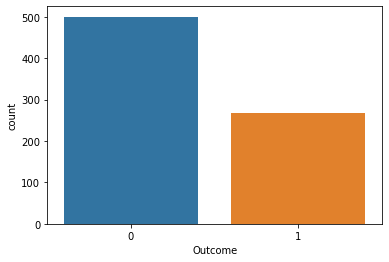

In [ ]:
import seaborn as sns
sns.countplot(diabetes['Outcome'],label="Count")

In [ ]:
from sklearn.model_selection import train_test_split

X = diabetes.loc[:, diabetes.columns != 'Outcome']
y = diabetes['Outcome']


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    stratify=diabetes['Outcome'], # data is split in a stratified fashion, using this as the class labels.
    random_state=66)#Controls the shuffling applied to the data before applying the split

In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.673


In [ ]:
"""
The accuracy on the training set is 100%, while the test set accuracy is much worse.
This is an indicative that the tree is overfitting and not generalizing well to new data.
Therefore, we need to apply pre-pruning to the tree.

We set max_depth=3, limiting the depth of the tree decreases overfitting.
This leads to a lower accuracy on the training set, but an improvement on the test set.

"""
from sklearn.metrics import classification_report
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

y_true, y_pred = y_test, tree.predict(X_test)
print(classification_report(y_true, y_pred))
print()

Accuracy on training set: 0.757
Accuracy on test set: 0.724
              precision    recall  f1-score   support

           0       0.72      0.95      0.82       165
           1       0.76      0.31      0.44        89

    accuracy                           0.72       254
   macro avg       0.74      0.63      0.63       254
weighted avg       0.73      0.72      0.69       254




In [ ]:
"""
#Feature Importance in Decision Trees
Feature importance rates how important each feature is for the decision a tree makes.
It is a number between 0 and 1 for each feature, where 0 means “not used at all” and 1 means “
perfectly predicts the target”.
The feature importances always sum to 1:
"""
print("Feature importances:\n{}".format(tree.feature_importances_))

Feature importances:
[0.02995094 0.75338836 0.         0.         0.         0.1748448
 0.         0.0418159 ]


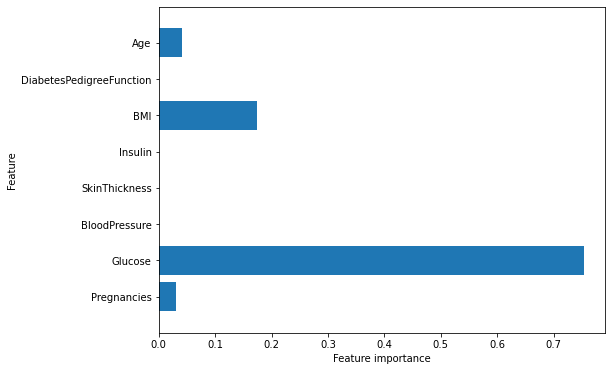

In [ ]:
#Then we can visualize the feature importances:
diabetes_features = [x for i,x in enumerate(diabetes.columns) if i!=8]
def plot_feature_importances_diabetes(model):
    plt.figure(figsize=(8,6))
    n_features = 8
    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), diabetes_features)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.ylim(-1, n_features)
plot_feature_importances_diabetes(tree)
plt.savefig('feature_importance')

In [ ]:
#Feature “Glucose” is by far the most important feature.